In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pickle
import numpy as np
import os,sys
sys.path.append('..')
from H2_6_31G_8Qbit import H2_6_31G_8Qbit

∣NK⟩ Tip: 😍 Love? 😡 Hate? these tips? Let us know at https://forms.gle/ej8eDGFRu2mww5mQ9

H2 分子基本信息
HF energy = -0.99749729 Ha
Total electrons = (1, 1)
Total basis functions = 4
H₂ FCI 基准能量
E0 = -1.05434745 Ha  |  激发能: 0.0000 eV
E1 = -0.95790573 Ha  |  激发能: 2.6243 eV
E2 = -0.66895227 Ha  |  激发能: 10.4871 eV
E3 = -0.55140192 Ha  |  激发能: 13.6859 eV
E4 = -0.02803278 Ha  |  激发能: 27.9275 eV
E5 = -0.01450343 Ha  |  激发能: 28.2956 eV
E6 = -0.00518297 Ha  |  激发能: 28.5492 eV
E7 = 0.02397075 Ha  |  激发能: 29.3425 eV
E8 = 0.23432390 Ha  |  激发能: 35.0666 eV
E9 = 0.25720575 Ha  |  激发能: 35.6892 eV
E10 = 0.49958128 Ha  |  激发能: 42.2846 eV
E11 = 0.50024484 Ha  |  激发能: 42.3026 eV

HF reference state: [0 0 0 1 0 0 0 1]
single_edges: [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (4, 7), (5, 6), (5, 7), (6, 7)]


In [7]:
with open('./data/26-10-23-06-16_history_K4_frozen4_deflation_MatrixFree_Pure.pkl', 'rb') as f:
    data = pickle.load(f)

molecule = H2_6_31G_8Qbit(K=8)

In [3]:
molecule.E_fcis

array([-1.05434745, -0.95790573, -0.66895227, -0.55140192, -0.02803278,
       -0.01450343, -0.00518297,  0.02397075,  0.2343239 ,  0.25720575,
        0.49958128,  0.50024484])

In [8]:
lam_history = data['lam']
lam_arr = np.asarray(lam_history)
lam_arr = lam_arr[-1,0]
lam_arr

np.float64(-0.028044211943266725)

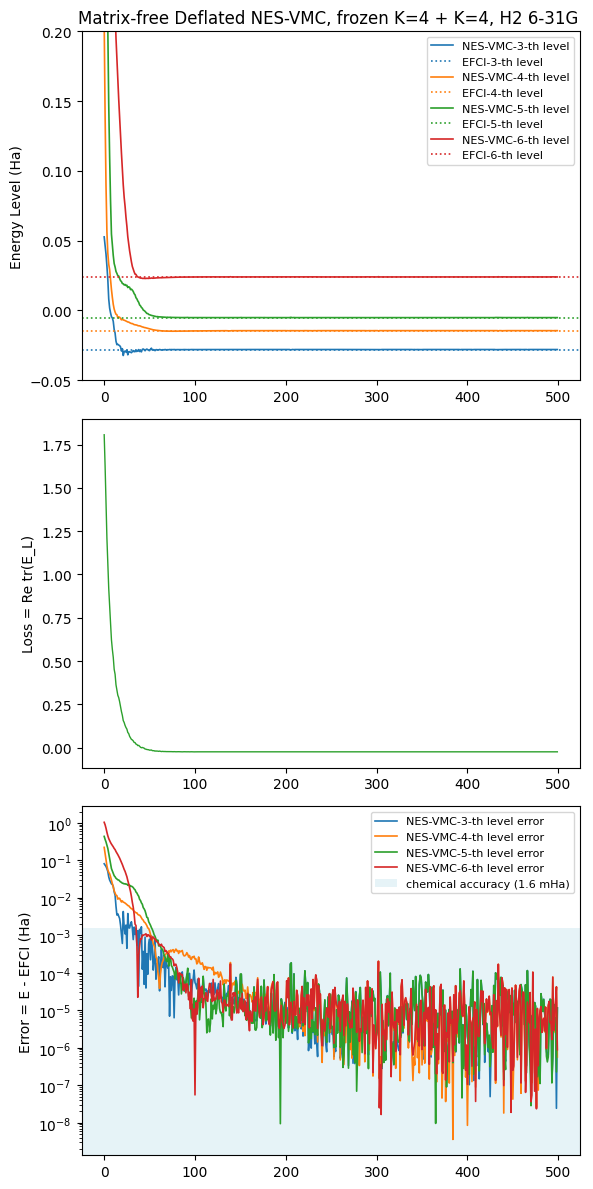

In [13]:
steps_history = data['steps']
lam_history = data['lam']
loss_history = data['loss']
diag_history = data['diag']
elapsed_history = data['elapsed_s']
K=4
N_ITER = len(steps_history)
steps_arr = np.asarray(steps_history)
lam_arr = np.asarray(lam_history)
loss_arr = np.asarray(loss_history)
elapsed = np.asarray(elapsed_history)
diag = {k: np.asarray([d[k] for d in diag_history]) for k in diag_history[0]}

# ========== 配色定义：K个能级一一对应 ==========
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]  # 第0条、第1条能级的固定颜色
fci_targets = molecule.E_fcis[4:8]

fig, axs = plt.subplots(3, 1, figsize=(6, 12))

# 子图0：λ_hat + FCI基准线，同能级同色
for k in range(K):
    axs[0].plot(steps_arr, lam_arr[:,k], lw=1.2, color=colors[k], label=f"NES-VMC-{3+k}-th level")
    axs[0].axhline(fci_targets[k], lw=1.2, linestyle=':', color=colors[k], label=f"EFCI-{3+k}-th level")
axs[0].set_ylabel("Energy Level (Ha)")
axs[0].set_title(f"Matrix-free Deflated NES-VMC, frozen K=4 + K={K}, H2 6-31G ")
axs[0].xaxis.set_major_formatter('{x:.0f}')
axs[0].set_ylim(-0.05,0.2)
axs[0].legend(fontsize=8)

# 子图1：Loss
m = np.isfinite(loss_arr)
axs[1].plot(steps_arr[m], loss_arr[m], lw=1.0, color="#2ca02c")
axs[1].set_ylabel("Loss = Re tr(E_L)")
axs[1].xaxis.set_major_formatter('{x:.0f}')

# 子图2：误差曲线，同能级复用上面的颜色
for k in range(K):
    error_k = np.abs(lam_arr[:,k] - fci_targets[k])
    axs[2].plot(steps_arr, error_k, lw=1.2, color=colors[k], label=f"NES-VMC-{3+k}-th level error")

axs[2].set_ylabel(f"Error = E - EFCI (Ha)")
axs[2].set_yscale("log")
axs[2].axhspan(0, 0.0016, facecolor="lightblue", alpha=0.3, zorder=0, label="chemical accuracy (1.6 mHa)")
axs[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"./graph/K=4+K=4.png")
